# 03 - Exploratory Data Analysis and Features

This notebook has five parts: A (sizing), B (transaction patterns), C (building features), D (feature analysis), and E (key findings).

Loading in the cleaned dataset


In [2]:

from google.colab import drive
from pathlib import Path
import pandas as pd

drive.mount("/content/drive")

PROJECT = Path("/content/drive/MyDrive/INFO320_AML")
CLEAN_FILE = PROJECT / "Data" / "Processed" / "SAML-D_cleaned.parquet"

df = pd.read_parquet(CLEAN_FILE)

df.info()
print("\nLaundering transactions:", df["Is_laundering"].sum())

print("\nDate and Timestamp types:")
print(df[["Date", "Timestamp"]].dtypes)


Mounted at /content/drive
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9504852 entries, 0 to 9504851
Data columns (total 13 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   Time                    string        
 1   Date                    datetime64[ns]
 2   Sender_account          string        
 3   Receiver_account        string        
 4   Amount                  float64       
 5   Payment_currency        category      
 6   Received_currency       category      
 7   Sender_bank_location    category      
 8   Receiver_bank_location  category      
 9   Payment_type            category      
 10  Is_laundering           int8          
 11  Laundering_type         category      
 12  Timestamp               datetime64[ns]
dtypes: category(6), datetime64[ns](2), float64(1), int8(1), string(3)
memory usage: 498.6 MB

Laundering transactions: 9873

Date and Timestamp types:
Date         datetime64[ns]
Timestamp    datetime

Cleaned dataset loaded with 9,504,852 transactions and 13 columns which now includes the timestamp column. The saved datatypes were preserved and 9,873 transactions are labeled as laundering.

## Part A - Sizing

I am counting one case for each sender account on each day it sent money. I chose this because an investigator reviews an account’s activity rather than individual payments. I am labeling a case as positive if at least one of the senders transactions that day were labeled as laundering.

In [3]:
account_days = df.groupby(["Sender_account", "Date"], as_index=False)["Is_laundering"].max()

print("Total sender account-days:", len(account_days))
print("Positive sender account-days:", account_days["Is_laundering"].sum())

Total sender account-days: 3683221
Positive sender account-days: 9064


the full 9,504,852 transactions formed 3,683,221 sender account days. of those 9,064 contained at least one outgoing transaction labeled as laundering which is about 1 positive case per 406 cases.

This also means some senders made multiple labeled transactionson the same day because there are 9,873 labeled laundering transactions but only 9,064 positive cases.

I am counting the total positive sender account days by month to see how many cases each month would contribute to training or evaluation before deciding my cutoff dates.

In [4]:

account_days["Month"] = account_days["Date"].dt.strftime("%Y-%m")

monthly_cases = account_days.groupby("Month").agg(
    total_cases=("Is_laundering", "size"),
    positive_cases=("Is_laundering", "sum"))

display(monthly_cases)


,total_cases,positive_cases
Month,,
2022-10,271285,640
2022-11,340816,736
2022-12,346141,827
2023-01,348607,880
2023-02,339035,888
2023-03,353783,849
2023-04,351248,888
2023-05,358255,789
2023-06,354880,913


Full months contain about 339,000-358,000 sender account days and 736-913 positive cases. October and August are lower because the data begind on Oct 7 and ends on Aug 23. Based on these counts im setting my designed cutoff date for my historical period at Dec 31 giving me 2,203 positive cases while Jan - Aug will be my deployment period containing 6,861 positive cases and leaves eight months for evaluating detection preformance.

Setting the historical cuttoff

In [5]:
CUTOFF = pd.Timestamp("2022-12-31")

I counted laundering transactions with distict sending accounts to create positive senders to see how the laundering activity is disriputed between senders

In [6]:
positive_tx = df.loc[df["Is_laundering"] == 1, ["Date", "Sender_account"]]
month = positive_tx["Date"].dt.strftime("%Y-%m")

monthly_cases["laundering_transactions"] = positive_tx.groupby(month).size()
monthly_cases["positive_senders"] = positive_tx.groupby(month)["Sender_account"].nunique()

display(monthly_cases)

,total_cases,positive_cases,laundering_transactions,positive_senders
Month,,,,
2022-10,271285,640,694,418
2022-11,340816,736,794,462
2022-12,346141,827,907,519
2023-01,348607,880,940,510
2023-02,339035,888,946,574
2023-03,353783,849,927,550
2023-04,351248,888,962,584
2023-05,358255,789,866,501
2023-06,354880,913,1024,535


In every month laundering transactions exceeded positive sender acount days and every month positive account days exceeded distict positive senders as well. This shows that some senders made multiple laundering transactions on the same day and some accounts had Laundering transactions on mulitple days within the month. For example in Oct there where 418 diffrent sending accounts with labeled laundering transctions. Those 418 accounts made 694 transactions labeled as laundering across across 640 sender account days meaning some senders made multiple laundering transactions on the same day and on multiple days in the month.

I am counting how many sender account days are involved in each laundering typology in each month and checked to verify that no sender day mixes two laundering schemes.

In [7]:
scheme_cases = df.loc[
    df["Is_laundering"] == 1,
    ["Sender_account", "Date", "Laundering_type"]].drop_duplicates()

scheme_cases["Month"] = scheme_cases["Date"].dt.strftime("%Y-%m")

typology_month = pd.crosstab(scheme_cases["Laundering_type"], scheme_cases["Month"])
display(typology_month)
print(typology_month.values.sum(), account_days["Is_laundering"].sum())

Month,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08
Laundering_type,,,,,,,,,,,
behavioural_change_1,34,13,24,22,12,20,48,16,42,33,13
behavioural_change_2,16,18,24,27,24,10,32,25,43,35,18
cash_withdrawal,57,112,96,124,88,105,66,98,113,88,119
cycle,15,1,54,46,59,44,24,58,32,41,8
deposit_send,54,90,69,85,96,104,105,86,81,107,68
fan_in,34,26,54,13,12,23,65,53,45,11,28
layered_fan_in,26,44,42,43,109,96,60,54,56,66,44
layered_fan_out,48,43,75,33,63,47,24,32,28,53,42
over_invoicing,2,8,3,5,4,3,4,11,6,4,4


9064 9064


Every positive sender day belongs to exavtly one typology and all 17 laundering typologies appear in every month, although their case counts are varied. Structuring is seen the most in each month at 1,870 positive sender days. Some schemes has very few individual months like cycle having onle one case in Nov and only 8 in Aug and over invoicing with only two cases in Oct. These smaller counts will make monthly detection performance harder to evaluate reliably.

Nine network related typologies make up 3,433 positive sender-days which is about 38% of all the positive cases. This supports testing whether network derived features improve detection beyond individual account behavior.

The nine network-related typologies are cycle, fan_in, fan_out, layered_fan_in, layered_fan_out, bipartite, stacked_bipartite, gather_scatter, and scatter_gather

I am counting positive sender account-days for each date and comparing the historical and deployment periods to see how much they vary and whether a review capacity of 50 cases per day is reasonable.

In [8]:

import numpy as np

daily_positives = account_days.groupby("Date")["Is_laundering"].sum()

period = np.where(
    daily_positives.index <= CUTOFF,
    "History",
    "Deployment")

display(daily_positives.groupby(period).describe())


,count,mean,std,min,25%,50%,75%,max
Deployment,235.0,29.195745,9.275230,7.0,22.0,29.0,36.50,51.0
History,86.0,25.616279,9.261138,8.0,18.0,26.5,31.75,48.0


In [9]:

print("Days with more than 50 positive cases:",
      (daily_positives > 50).sum())


Days with more than 50 positive cases: 3


During the historical period, there were an average of 25.6 positive sender account-days per day, compared to 29.2 during deployment. The daily number varied considerably, ranging from 8 to 48 in history and 7 to 51 in deployment.

Only 3 of the 321 days had more than 50 positive cases. This supports using a review capacity of 50 sender account-days per day, since it exceeds the actual number of positive cases on nearly every day.

But reviewing 50 cases a day over 235 days means 11,750 reviews, but there are only 6,861 positive cases in deployment. Even a perfect system would fill the remaining slots with normal cases, so the highest possible precision is about 58%. I will compare model precision to this ceiling instead of 100%

Im comparing the historical and deployment periods to see how many sender account days and positive cases are in each.

In [10]:

account_days["Period"] = np.where(
    account_days["Date"] <= CUTOFF,
    "History",
    "Deployment")

period_summary = account_days.groupby("Period").agg(
    days=("Date", "nunique"),
    sender_days=("Is_laundering", "size"),
    positive_cases=("Is_laundering", "sum"))

period_summary["positive_rate_%"] = (
    period_summary["positive_cases"] / period_summary["sender_days"] * 100).round(3)

period_summary["positives_per_day"] = (
    period_summary["positive_cases"] / period_summary["days"]).round(1)

display(period_summary)


,days,sender_days,positive_cases,positive_rate_%,positives_per_day
Period,,,,,
Deployment,235,2724979,6861,0.252,29.2
History,86,958242,2203,0.230,25.6


The historical period contains 958,242 sender account-days with 2,203 positive cases (0.230%). The deployment period contains 2,724,979 sender account-days with 6,861 positive cases (0.252%).

Both the positive case and per day rate increased slightly during deployment, from an average of 25.6 to 29.2 cases per day. This split gives me 86 days of historical data to develop the initial detection system and 235 days to evaluate its performance over time.

I am calculating how accurate a system would appear if it classified every transaction and sender account day as normal.

In [11]:

transaction_accuracy = (1 - df["Is_laundering"].mean()) * 100
sender_day_accuracy = (1 - account_days["Is_laundering"].mean()) * 100

print(f"Transaction accuracy: {transaction_accuracy:.2f}%")
print(f"Sender-day accuracy: {sender_day_accuracy:.2f}%")


Transaction accuracy: 99.90%
Sender-day accuracy: 99.75%


A system that classifies every transaction as normal would achieve 99.90% accuracy, while a system that classifies every sender account day as normal would achieve 99.75% accuracy.

Despite these high accuracy scores the system would fail to detect any laundering. This shows why accuracy alone is misleading for this dataset and why I will evaluate the models based on how many positive cases they identify within the bank's daily review capacity.

# Part A Decisions
*   Unit: sender account-day (3,683,221 cases; 9,064 positive)
*   History: Oct 7–Dec 31, 2022 (86 days; 2,203 positive)
*   Deployment: Jan 1–Aug 23, 2023 (235 days; 6,861 positive)
*   Capacity: 50 reviews per day (recall ceiling 99.96%; precision ceiling ~58%)
*   Metric: positives caught within capacity, not accuracy
*   Labels: used to understand the data and set rule thresholds, never to choose features









# Part B Transaction Patterns (History)

I'm examining Historical transactions only from October through December 2022 to understand transaction amounts, payment types, and laundering patterns before building the model features.


Seperating the historical transactions and counting them

In [12]:

history_tx = df[df["Date"] <= CUTOFF]

print("History transactions:", len(history_tx))


History transactions: 2506616


Im comparing transactions sent in UK pounds but received in different currencies to see whether Amount is recorded as payment or recieved currency

In [13]:
gbp_tx = history_tx[history_tx["Payment_currency"] == "UK pounds"]

currency_check = gbp_tx.groupby(
    "Received_currency", observed=True)["Amount"].agg(["count", "median"])

display(currency_check.sort_values("count", ascending=False))


,count,median
Received_currency,,
UK pounds,2218750,5920.290
Euro,57163,7244.250
Mexican Peso,12956,7549.685
Naira,12149,7255.470
Albanian lek,12117,7286.180
US dollar,12084,7421.700
Pakistani rupee,11790,7390.015
Moroccan dirham,11671,7140.210
Yen,11226,6959.400


When I looked at transactions sent in UK pounds, the median amounts were fairly similar regardless of the currency received. For example, the median was 7,244 for euros, 6,959 for yen, and 7,255 for naira.

This suggests that Amount is likely recorded in the payment currency rather than being converted to the received currency, But this doesn't confirm it completely. I'll use the payment currency when comparing transaction amounts and building my features.

Im looking at how transactions amounts are distributed to see how much they vary and if unusally large transactions affect the data.

In [14]:

display(history_tx["Amount"].describe().round(2))

print("Skewness:", round(history_tx["Amount"].skew(), 2))
print("Kurtosis:", round(history_tx["Amount"].kurt(), 2))
currency_amounts = history_tx.groupby("Payment_currency", observed=True)["Amount"].quantile([0.50, 0.95, 0.99]).unstack()

display(currency_amounts.round(2))


,Amount
count,2506616.00
mean,8764.17
std,26756.99
min,4.23
25%,2112.47
50%,6094.50
75%,10375.82
max,11837365.32


Skewness: 103.27
Kurtosis: 32542.08


,0.50,0.95,0.99
Payment_currency,,,
Albanian lek,7342.73,22927.98,44870.68
Dirham,7195.95,22158.20,46896.02
Euro,7579.94,24750.40,53559.73
Indian rupee,7515.12,22806.78,56194.96
Mexican Peso,7062.91,24686.40,46244.77
Moroccan dirham,7304.95,23552.48,49225.36
Naira,7522.22,24039.21,60005.56
Pakistani rupee,7653.32,23850.52,44121.42
Swiss franc,7334.35,22778.19,55391.16


Transaction amounts are heavily skewed, with a skewness of 103.27 and kurtosis of 32,542.08. The skewness of 103.27 shows that most transactions are relatively small compared to a few extremely large ones. The kurtosis of 32,542.08 further shows how extreme some of those large transactions are. The largest transaction was over 11.8 million, while the median was only 6,094.50. Because of these large differences, I'll use medians instead of averages and a log scale to better show how amounts are distributed.

Looking at the breakdown by currency, most median transaction amounts were between 7,000 and 7,700, with UK pounds being the lowest at about 6,030. This shows similar numerical amounts across currencies, although it doesn't mean the currencies have the same actual value.


Im plotting transaction amounts on a log scale to better see their distribution without the largest transactions dominating the grapgh

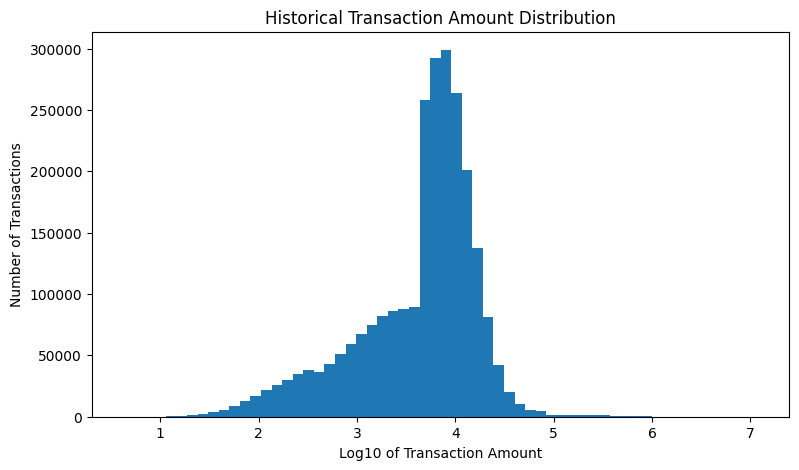

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(np.log10(history_tx["Amount"]), bins=60)

plt.title("Historical Transaction Amount Distribution")
plt.xlabel("Log10 of Transaction Amount")
plt.ylabel("Number of Transactions")

plt.show()


The histogram makes the distribution easier to see, with most transactions concentrated around amounts of a few thousand. It also shows how far some unusually large transactions extend beyond the typical range.

I'm using the IQR method to identify transactions with unusually large amounts compared to others in the same currency. This method looks at the middle 50% of transactions and flags amounts that are more than 1.5 times that range above the 75th percentile.

In [16]:

quartiles = history_tx.groupby(
    "Payment_currency", observed=True)["Amount"].quantile([0.25, 0.75]).unstack()

quartiles.columns = ["Q1", "Q3"]

quartiles["IQR"] = quartiles["Q3"] - quartiles["Q1"]
quartiles["Upper_limit"] = quartiles["Q3"] + 1.5 * quartiles["IQR"]

limits = history_tx["Payment_currency"].map(
    quartiles["Upper_limit"]).astype(float)

outliers = history_tx["Amount"] > limits

display(quartiles.round(2))

print("Outlier transactions:", outliers.sum())
print("Percent of transactions:", round(outliers.mean() * 100, 2))


,Q1,Q3,IQR,Upper_limit
Payment_currency,,,,
Albanian lek,4223.82,12050.34,7826.52,23790.13
Dirham,4671.10,11819.22,7148.12,22541.40
Euro,4844.11,11831.69,6987.58,22313.06
Indian rupee,4801.78,12118.68,7316.89,23094.01
Mexican Peso,4610.12,11293.23,6683.10,21317.88
Moroccan dirham,4800.12,11587.12,6787.00,21767.63
Naira,4784.70,11821.51,7036.81,22376.72
Pakistani rupee,5005.72,11989.86,6984.14,22466.07
Swiss franc,4662.27,11655.35,6993.07,22144.96


Outlier transactions: 111668
Percent of transactions: 4.45


Using the IQR method, I identified 111,668 transactions which is about 4.45% as high-value outliers. The upper limits were fairly similar across currencies, generally in the range of 21,000 to 24,000.

even though 4.45% seems small, that still represents over 111,000 transactions in only 86 days, or about 1,300 per day. With the bank only able to review 50 cases daily, using unusual amounts alone would generate far too many alerts. I'll keep these transactions in the dataset and use unusually large amounts as one of many indicators rather than automatically flagging them as suspicious.

Im lookin at the differnt payment types in the historical data to see how transactions are categorized and identify which ones involve cash.

In [17]:

display(history_tx["Payment_type"].value_counts())

,count
Payment_type,
Credit card,530604
Cheque,530013
Debit card,529896
ACH,529661
Cross-border,246866
Cash Withdrawal,80142
Cash Deposit,59434


The dataset contains seven payment types. Credit card, cheque (British spelling of Ckeck), debit card, and ACH transactions are the most common, and cash deposits and withdrawals are less frequent.

There were 80,142 cash withdrawals and 59,434 cash deposits. I'll use these two payment types when creating the cash transaction indicator for my models.

Im comparing transactions labeled as cross border with the sender and reciver banks to see if they match.

In [18]:

payment_crossborder = history_tx["Payment_type"] == "Cross-border"

location_crossborder = (
    history_tx["Sender_bank_location"] != history_tx["Receiver_bank_location"])

display(pd.crosstab(
    payment_crossborder,
    location_crossborder,
    rownames=["Cross-border payment type"],
    colnames=["Different bank countries"]))

print("Disagreements:", (payment_crossborder != location_crossborder).sum())


Different bank countries,False,True
Cross-border payment type,,
False,2259637,113
True,0,246866


Disagreements: 113


The two definitions were almost identical, with only 113 disagreements out of over 2.5 million transactions. Every transaction that was labeled cross border involved banks in different countries, but 113 transactions that were not labeled as cross border payment types also involved different countries.

I'll use the sender and receiver bank locations to identify cross border activity so these additional transactions aren't missed.

I'm looking more closely at the 113 transactions to see what payment types they were, whether any were labeled as laundering, and which countries were involved.

In [19]:

missed_crossborder = history_tx[(~payment_crossborder) & location_crossborder]

display(missed_crossborder["Payment_type"].value_counts())

print("Laundering transactions:",missed_crossborder["Is_laundering"].sum())

display( missed_crossborder.groupby(["Sender_bank_location", "Receiver_bank_location"],observed=True).size().sort_values(ascending=False).head(10))


,count
Payment_type,
Cash Withdrawal,113
ACH,0
Cash Deposit,0
Cheque,0
Credit card,0
Cross-border,0
Debit card,0


Laundering transactions: 113


Sender_bank_location  Receiver_bank_location
UK                    India                     28
                      Nigeria                   22
                      Mexico                    20
                      Austria                   13
                      Morocco                   10
                      Pakistan                   8
                      UAE                        7
                      USA                        5
dtype: int64

All 113 missing transactions from the cross border label were classified as Cash Withdrawals and all were labeled as laundering. Every transaction involved a sender bank in the UK and a receiver bank in another country, most commonly India (28), Nigeria (22), and Mexico (20).

This is interesting because none of these transactions were classified as Cross-border, even though they involved banks in different countries. It also shows why using bank locations is a better way to identify international activity in this dataset, but this may be a pattern created by the synthetic dataset rather than something that would necessarily occur in real banking transactions.

Im checking currency missmatches to see how many transactions are sent and receibved in dfferent currencies to see how common a currency mismatch is.

In [20]:

currency_mismatch = (
    history_tx["Payment_currency"] != history_tx["Received_currency"])

print("Currency mismatches:", currency_mismatch.sum())
print("Percent of transactions:", round(currency_mismatch.mean() * 100, 2))


Currency mismatches: 286743
Percent of transactions: 11.44


Of the 2.5 million historical transactions 286,743 which is 11.44% were sent and received in different currencies. The remaining 88.56% of transactions used the same currency.

I'll use this to create a currency mismatch feature that identifies whether a sender made any payments involving different currencies that day.

I'm comparing the currency mismatches with cross-border transactions to see how often currency exchanges happen between banks in the same country versus different countries.

In [21]:

display(pd.crosstab(
    currency_mismatch,
    location_crossborder,
    rownames=["Currency Mismatch"],
    colnames=["Cross-border"],
    margins=True))


Cross-border,False,True,All
Currency Mismatch,,,
False,2218891,982,2219873
True,40746,245997,286743
All,2259637,246979,2506616


Most currency mismatches were also cross-border transactions which is to be expected with 245,997 involving banks in different countries. However, 40,746 transactions used different currencies even though both banks were in the same country. Another 982 cross-border transactions used the same currency.

I'm looking closer at the 40,746 domestic currency mismatches to see which payment types and countries they involve and if they are laundering.

In [22]:

domestic_mismatch = history_tx[
    currency_mismatch & ~location_crossborder]

display(domestic_mismatch["Payment_type"].value_counts())

display(domestic_mismatch["Sender_bank_location"].value_counts())

print("Laundering transactions:",
      domestic_mismatch["Is_laundering"].sum())


,count
Payment_type,
Debit card,10017
Cheque,9975
Credit card,9946
ACH,9661
Cash Deposit,1147
Cash Withdrawal,0
Cross-border,0


,count
Sender_bank_location,
UK,40739
Austria,1
Switzerland,1
France,1
Netherlands,1
Italy,1
Pakistan,1
USA,1
Albania,0


Laundering transactions: 178


Looking closer at the 40,746 domestic currency mismatches, I found that almost all involved UK banks. Most of them were debit card, cheque, credit card, or ACH transactions.

Only 178 were labeled as laundering which was fewer than I expected. But that represents about 0.44% of these transactions and when compared to just 0.096% across all historical transactions its significatlly higher. So even though most domestic currency mismatches were normal, their laundering rate was about 4.6 times higher than the overall average in this period.

This suggests currency mismatch could be a useful indicator, but it wouldn't be enough to flag transactions on its own.

I'm checking how many historical transactions were sent to the four high risk countries designated in dataset (Mexico, Turkey, Morocco, and UAE)

In [23]:

high_risk_countries = ["Mexico", "Turkey", "Morocco", "UAE"]

high_risk_tx = history_tx[
    history_tx["Receiver_bank_location"].isin(high_risk_countries)]

display(high_risk_tx["Receiver_bank_location"].value_counts())

print("Total transactions:", len(high_risk_tx))
print("Percent of transactions:", round(len(high_risk_tx) / len(history_tx) * 100, 2))


,count
Receiver_bank_location,
Mexico,11813
Morocco,10303
UAE,8958
Turkey,8451
Austria,0
Albania,0
Italy,0
India,0
France,0


Total transactions: 39525
Percent of transactions: 1.58


Out of the 2.5 million historical transactions, 39,525 which is 1.58% of transactions, were sent to banks in the four countries identified as high-risk in the research paper. Mexico had the most with 11,813 transactions, followed by Morocco, the UAE, and Turkey.

These four countries only account for a small percentage of all transactions. I'll use them to create a feature that checks whether a sender made any payments to one of these countries during the day.

## Laundering Rates by Category

These features come from standard AML red flags (cash, cross-border activity, currency conversion, and high-risk jurisdictions). The rates below confirm they are informative in this data, but I am not adding or removing features based on them, since a bank would only know outcomes for the cases it investigated.

I'm comparing laundering rates across the different payment types to see how often each type of transaction was labeled as laundering in the historical data.

In [24]:

payment_rates = history_tx.groupby("Payment_type", observed=True)["Is_laundering"].agg(["count", "sum", "mean"])

payment_rates.columns = ["Transactions", "Laundering", "Rate"]

payment_rates["Rate"] = (payment_rates["Rate"] * 100).round(3)

display(payment_rates.sort_values("Rate", ascending=False))


,Transactions,Laundering,Rate
Payment_type,,,
Cash Deposit,59434,303,0.510
Cash Withdrawal,80142,330,0.412
Cross-border,246866,638,0.258
Credit card,530604,291,0.055
ACH,529661,285,0.054
Cheque,530013,273,0.052
Debit card,529896,275,0.052


Cash deposits had the highest laundering rate at 0.510%, followed by cash withdrawals at 0.412% and cross-border payments at 0.258%. The other four payment types were much lower they were all around 0.05%.

What stood out to me was that cash deposits had a laundering rate that is over five times higher than the historical average of 0.096%. but even among cash deposits, more than 99% of transactions were normal.

This shows that certain payment types are associated with higher laundering rates, but the payment type alone isn't enough to determine whether a transaction is suspicious on its own.

I'm comparing laundering rates for transactions between banks in the same country and banks in different countries.

In [25]:

crossborder_rates = history_tx.groupby(
    location_crossborder)["Is_laundering"].agg(["count", "sum", "mean"])

crossborder_rates.columns = ["Transactions", "Laundering", "Rate"]
crossborder_rates["Rate"] = (crossborder_rates["Rate"] * 100).round(3)

display(crossborder_rates)


,Transactions,Laundering,Rate
False,2259637,1644,0.073
True,246979,751,0.304


Transactions between banks in different countries had a laundering rate of 0.304%, compared to 0.073% for transactions within the same country. This means that cross border transactions had a laundering rate about 4.2 times higher than transactions in the same country.

Using bank locations, I identified 751 laundering transactions involving different countries, compared to only 638 classified under the Cross border payment type. The difference comes from the 113 cash withdrawals I investigated earlier, which involved banks in different countries but weren't labeled Cross border.

This further supports my decision to use bank locations rather than payment types to identify cross border activity.

I'm comparing laundering rates for transactions that use the same currency and those sent and received in different currencies.

In [26]:

mismatch_rates = history_tx.groupby(
    currency_mismatch)["Is_laundering"].agg(["count", "sum", "mean"])

mismatch_rates.columns = ["Transactions", "Laundering", "Rate"]
mismatch_rates["Rate"] = (mismatch_rates["Rate"] * 100).round(3)

display(mismatch_rates)


,Transactions,Laundering,Rate
False,2219873,1482,0.067
True,286743,913,0.318


Transactions involving different currencies had a laundering rate of 0.318%, compared to 0.067% for transactions using the same currency, making the laundering rate about 4.8 times higher for mismatched currencies.

This one also connects to my earlier investigation of the 40,746 domestic currency mismatches, where I found that 178 were laundering. Those domestic mismatches had an even higher laundering rate of 0.44%.

This shows that currency mismatches may be useful for identifying suspicious activity, even when both banks are in the same country. Even though most currency mismatches were still normal transactions.

I'm comparing laundering rates for transactions sent to the four high risk countries Mexico, Turkey, Morocco, and the UAE against transactions sent to all other countries.

In [27]:

high_risk_flag = history_tx["Receiver_bank_location"].isin(high_risk_countries)

high_risk_rates = history_tx.groupby(high_risk_flag)["Is_laundering"].agg(["count", "sum", "mean"])

high_risk_rates.columns = ["Transactions", "Laundering", "Rate"]
high_risk_rates["Rate"] = (high_risk_rates["Rate"] * 100).round(3)

display(high_risk_rates)


,Transactions,Laundering,Rate
Receiver_bank_location,,,
False,2467091,2210,0.090
True,39525,185,0.468


Transactions sent to the four high risk countries had a laundering rate of 0.468%, compared to 0.090% for transactions sent elsewhere. This means the laundering rate was about 5.2 times higher.

But out of the 39,525 transactions sent to these countries, only 185 were labeled as laundering. So while these countries had a higher laundering rate, most transactions were still normal. This shows why sending money to one of these countries shouldn't automatically mean a transaction is suspicious.

# Part B Key Findings and Decisions

## Findings
*   Amounts share one scale across currencies (median about 7,000)

* Extreme skew (skew 103), so medians and log scale

* IQR outliers: about 1,300 a day, too many to alert on

* Bank location catches 113 laundering cash withdrawals that the cross-border payment type misses (possibly an artifact of dataset creation)

* Currency mismatch largely overlaps cross-border

* Cash, cross-border, mismatch, and high-risk countries: laundering rates 4–5× the average, but over 99% normal

## Decisions
* Amount: largest payment ÷ October–November median for its payment currency

* Cash: Cash Deposit or Cash Withdrawal

* Cross-border: sender location ≠ receiver location

* Currency mismatch: payment currency ≠ received currency

* High-risk: receiver in Mexico, Turkey, Morocco, or UAE

* Check cross-border/mismatch redundancy in Part D



# Part C - Building Sender Day Features

I'm starting with two weeks of transactions to test that my feature calculations work correctly before running them on the full dataset.

I used SAMPLE = True to test my calculations on the first two weeks of transactions before processing the full dataset. Changing it to False runs the same calculations on all transactions. I've kept the sample findings to document my initial testing and will clearly label sample and full-run results where they differ.

In [28]:

SAMPLE = False

work = df[df["Date"] <= "2022-10-20"] if SAMPLE else df

print("Transactions:", len(work))
print("Date range:", work["Date"].min(), "to", work["Date"].max())


Transactions: 9504852
Date range: 2022-10-07 00:00:00 to 2023-08-23 00:00:00


My two week sample contains 400,937 transactions and runs from Oct 7 -20

The full dataset contains 9,504,852 transactions from October 7, 2022, through August 23, 2023.

Im converting the sender and receiver account IDs into numbers to make grouping tracking account activity faster when building my features

In [29]:

codes, uniques = pd.factorize(
    pd.concat([work["Sender_account"], work["Receiver_account"]]))

tx = work[["Date", "Amount", "Payment_currency","Payment_type", "Is_laundering", "Laundering_type"]].copy()

tx["sender_id"] = codes[:len(work)]
tx["receiver_id"] = codes[len(work):]

display(tx.head())
print("Unique accounts:", len(uniques))


,Date,Amount,Payment_currency,Payment_type,Is_laundering,Laundering_type,sender_id,receiver_id
0,2022-10-07,1459.15,UK pounds,Cash Deposit,0,normal_cash_deposits,0,17127
1,2022-10-07,6019.64,UK pounds,Cross-border,0,normal_fan_out,1,292715
2,2022-10-07,14328.44,UK pounds,Cheque,0,normal_small_fan_out,2,292716
3,2022-10-07,11895.00,UK pounds,ACH,0,normal_fan_in,3,13773
4,2022-10-07,115.25,UK pounds,Cash Deposit,0,normal_cash_deposits,4,4001


Unique accounts: 855460


I'm creating indicators for cross-border payments, currency mismatches, high-risk countries, cash transactions, and unusually large amounts using the definitions from Part B.

In [30]:
tx["cross_border"] = (work["Sender_bank_location"] != work["Receiver_bank_location"])

tx["mismatch"] = (work["Payment_currency"] != work["Received_currency"])

tx["high_risk"] = work["Receiver_bank_location"].isin(high_risk_countries)

tx["cash"] = work["Payment_type"].isin(["Cash Deposit", "Cash Withdrawal"])
# Using October-November medians so December doesn't affect training features
currency_median = (history_tx[history_tx["Date"] < "2022-12-01"].groupby("Payment_currency", observed=True)["Amount"].median())

tx["amount_ratio"] = (tx["Amount"] / tx["Payment_currency"].map(currency_median).astype(float))
display(tx.head())

,Date,Amount,Payment_currency,Payment_type,Is_laundering,Laundering_type,sender_id,receiver_id,cross_border,mismatch,high_risk,cash,amount_ratio
0,2022-10-07,1459.15,UK pounds,Cash Deposit,0,normal_cash_deposits,0,17127,False,False,False,True,0.242297
1,2022-10-07,6019.64,UK pounds,Cross-border,0,normal_fan_out,1,292715,True,True,True,False,0.999582
2,2022-10-07,14328.44,UK pounds,Cheque,0,normal_small_fan_out,2,292716,False,False,False,False,2.379286
3,2022-10-07,11895.00,UK pounds,ACH,0,normal_fan_in,3,13773,False,False,False,False,1.975205
4,2022-10-07,115.25,UK pounds,Cash Deposit,0,normal_cash_deposits,4,4001,False,False,False,True,0.019138


The first four indicators show whether a transaction meets each condition, and the amount ratio shows how large a payment is compared to the typical amount for its currency. These will be combined into daily account features in the next step.

I'm grouping transactions by sender account and date to calculate each account's daily activity and risk indicators. Each sender will have one row per day, even if they made multiple transactions.

In [31]:


features = tx.groupby(["sender_id", "Date"]).agg(
    payments_today=("Amount", "size"),
    receivers_today=("receiver_id", "nunique"),
    any_cross_border=("cross_border", "max"),
    cross_border_share_today=("cross_border", "mean"),
    any_mismatch=("mismatch", "max"),
    any_high_risk=("high_risk", "max"),
    any_cash=("cash", "max"),
    max_amount_ratio=("amount_ratio", "max"),
    total_amount_ratio_today=("amount_ratio", "sum"),
    label=("Is_laundering", "max")).reset_index()


# Save laundering types for evaluation, not for training
typology = tx[tx["Is_laundering"] == 1].groupby(["sender_id", "Date"], observed=True)["Laundering_type"].first()

features = features.join(typology, on=["sender_id", "Date"])

display(features.head())
print("Sender-days:", len(features))
print("Positive sender-days:", features["label"].sum())


,sender_id,Date,payments_today,receivers_today,any_cross_border,cross_border_share_today,any_mismatch,any_high_risk,any_cash,max_amount_ratio,total_amount_ratio_today,label,Laundering_type
0,0,2022-10-07,1,1,False,0.0,False,False,True,0.242297,0.242297,0,NaN
1,0,2022-11-16,1,1,False,0.0,False,False,True,0.780356,0.780356,0,NaN
2,0,2023-01-05,1,1,False,0.0,False,False,True,0.527244,0.527244,0,NaN
3,0,2023-01-20,1,1,False,0.0,False,False,True,0.810274,0.810274,0,NaN
4,0,2023-01-25,1,1,False,0.0,False,False,True,0.132670,0.132670,0,NaN


Sender-days: 3683221
Positive sender-days: 9064


The 400,937 sample transactions were grouped into 151,372 sender account-days, including 435 positive cases. Each sender now has one row for every day they made payments, with their daily activity and risk indicators combined.

The full dataset contained 3,683,221 sender-days, including 9,064 positive cases, matching the results from Part A.

I also calculated the share of payments that were cross border and the total daily amount relative to Oct- Nov medians for each currency.

I included the laundering labels and types for later evaluation but won't be used as model features.

I'm calculating how many payments each account sent and received over the previous seven days. Im going to exclude the current day so the features only use past activity.I'm also comparing todays payment count with the recent daily average to identify sudden increases in activity.

In [32]:


sent_daily = features[["sender_id", "Date", "payments_today"]].rename(
    columns={"sender_id": "account", "payments_today": "sent"})

received_daily = tx.groupby(["receiver_id", "Date"]).size().reset_index(name="received")
received_daily = received_daily.rename(columns={"receiver_id": "account"})

daily = sent_daily.merge(received_daily, on=["account", "Date"], how="outer").fillna(0)
daily = daily.sort_values(["account", "Date"])

# Im counting payments from the previous 7 days, excluding today
past_week = daily.groupby("account").rolling(
    "7D", on="Date", closed="left")[["sent", "received"]].sum().reset_index().fillna(0)

past_week = past_week.rename(columns={
    "sent": "payments_prior_7d",
    "received": "received_prior_7d"})

features = features.merge(
    past_week,
    left_on=["sender_id", "Date"],
    right_on=["account", "Date"],
    how="left").drop(columns="account")

features["payment_spike"] = (
    features["payments_today"] /
    (features["payments_prior_7d"] / 7 + 1))

display(features[[
    "sender_id", "Date", "payments_today",
    "payments_prior_7d", "received_prior_7d", "payment_spike"]].head(10))


,sender_id,Date,payments_today,payments_prior_7d,received_prior_7d,payment_spike
0,0,2022-10-07,1,0.0,0.0,1.000
1,0,2022-11-16,1,0.0,0.0,1.000
2,0,2023-01-05,1,0.0,0.0,1.000
3,0,2023-01-20,1,0.0,0.0,1.000
4,0,2023-01-25,1,1.0,0.0,0.875
5,0,2023-02-20,1,0.0,0.0,1.000
6,0,2023-03-14,1,0.0,0.0,1.000
7,0,2023-03-17,1,1.0,0.0,0.875
8,0,2023-04-03,1,0.0,0.0,1.000
9,0,2023-05-22,1,0.0,0.0,1.000


The seven-day features appear to be working correctly. One confirming detail was sender 1's previous payment count dropped from 106 on October 14 to 6 on October 15 because their 102 payments from October 7 were no longer within the seven-day window.

The payment spike feature also shows changes in activity. However, accounts with no previous activity can have high spike values, so this won't always indicate unusual behavior.

The seven-day payment counts exclude the current day's activity, while payment spike compares today's activity against those earlier transactions.

I'm measuring how many different accounts are sending money to each receiver on the same day. This will help to identify accounts that are sending money to receivers that are collecting payments from multiple sources.

In [33]:

# Removed old columns so I can rerun this cell
tx = tx.drop(columns="receiver_fanin", errors="ignore")
features = features.drop(columns="max_receiver_fanin", errors="ignore")
fanin = tx.groupby(["receiver_id", "Date"])["sender_id"].nunique()
fanin = fanin.rename("receiver_fanin")

tx = tx.join(fanin, on=["receiver_id", "Date"])

max_fanin = tx.groupby(["sender_id", "Date"])["receiver_fanin"].max()
max_fanin = max_fanin.rename("max_receiver_fanin")

features = features.join(max_fanin, on=["sender_id", "Date"])

display(features[["sender_id", "Date", "receivers_today", "max_receiver_fanin"]].head(10))


,sender_id,Date,receivers_today,max_receiver_fanin
0,0,2022-10-07,1,1
1,0,2022-11-16,1,1
2,0,2023-01-05,1,1
3,0,2023-01-20,1,1
4,0,2023-01-25,1,1
5,0,2023-02-20,1,1
6,0,2023-03-14,1,1
7,0,2023-03-17,1,1
8,0,2023-04-03,1,1
9,0,2023-05-22,1,1


All 10 rows here had a receiver fan in of 1 meaning that none of these senders paid a receiver that had received money from another sender on the same day.

Below i will further investigate the distribution across the full sample to see how ofter receivers get payments from multiple senders.

In [34]:
features["max_receiver_fanin"].value_counts().sort_index()

,count
max_receiver_fanin,
1,3287137
2,114526
3,64719
4,28500
5,8860
6,2172
7,6335
8,7304
9,8433


The results show the first 10 rows were misleading. Most sender days at 89.1% had a receiver fan in of 1, but the remaining 10.9% had values ranging from 2 to 20. This shows that some accounts are sending money to receivers that collect payments from multiple sources.

In the full dataset, most sender-days at 89.2% had a receiver fan-in of 1, but the remaining 10.8% had values ranging from 2 to 22. The results were very similar to the initial two-week sample.

Now that we've created all 13 features I want to check that everything worked before running the calculations on the full dataset. So im checking for duplicate sender days, missing valuse, and whether the seven day payment counts match the original transactions.

In [35]:

print("Sender-days:", len(features))
print("Positive sender-days:", features["label"].sum())
print("Duplicate sender-days:", features.duplicated(["sender_id", "Date"]).sum())
print("Missing feature values:", features.drop(columns="Laundering_type").isna().sum().sum())

# Checking if the 7-day counts matchthe original transactions
day = pd.Timestamp("2022-10-15")
past = tx[(tx["Date"] >= day - pd.Timedelta(days=7)) & (tx["Date"] < day)]

row = features[
    (features["sender_id"] == 1) & (features["Date"] == day)].iloc[0]

print("Sent - original:", (past["sender_id"] == 1).sum())
print("Sent - feature:", row["payments_prior_7d"])
print("Received - original:", (past["receiver_id"] == 1).sum())
print("Received - feature:", row["received_prior_7d"])

print("Number of model features:", len(features.columns) - 4)


Sender-days: 3683221
Positive sender-days: 9064
Duplicate sender-days: 0
Missing feature values: 0
Sent - original: 6
Sent - feature: 6.0
Received - original: 1
Received - feature: 1.0
Number of model features: 13


### Sample
All my checks passed. The sample contains 151,372 sender-days, including the 435 positive cases, with no duplicate sender days or missing feature values.

The seven day payment counts also matched the original transactions for the account I checked, and all 13 of my model features are present.

These results give me confidence that the feature calculations are working correctly on the sample before applying them to the full dataset.

### Full Dataset
All checks passed on the full dataset as well. I ended up with 3,683,221 sender-days, including 9,064 positive cases, with no duplicate sender-days or missing feature values.

The seven-day payment counts also matched the original transactions for the account I checked, and all 13 model features are present.

Now that all 13 features passed validation on the 2 week sample, im ready to apply the calculations to all 9.5 million transactions. I'll check the final sender-day counts, restore the original account IDs, and save the results for modeling in Notebook 04

In [36]:

print("Total sender-days:", len(features))
print("Positive sender-days:", features["label"].sum())
print("Duplicate sender-days:", features.duplicated(["sender_id", "Date"]).sum())

# Separating historical and deployment data into periods
features["Period"] = np.where(features["Date"] <= CUTOFF, "History", "Deployment")

print(features["Period"].value_counts())

features["Sender_account"] = uniques.take(features["sender_id"])

output_path = PROJECT / "Data" / "Processed" / "sender_day_features.parquet"
features.to_parquet(output_path, index=False)

print("Saved to:", output_path)



Total sender-days: 3683221
Positive sender-days: 9064
Duplicate sender-days: 0
Period
Deployment    2724979
History        958242
Name: count, dtype: int64
Saved to: /content/drive/MyDrive/INFO320_AML/Data/Processed/sender_day_features.parquet


The full dataset successfully processed and saved 3,683,221 sender days including 9,064 positive cases.

I also restored the original sender account IDs and separated the data into 958,242 historical sender-days and 2,724,979 deployment sender-days then saved the final dataset as a Parquet file for use in the 04 modeling notebook.

### Final Feature Summary

I created 13 features to measure daily account activity, transaction risk, changes in behavior, and relationships between accounts.

| Feature | What it measures |
|---|---|
| `payments_today` | Number of payments sent today |
| `receivers_today` | Number of different receivers today |
| `payments_prior_7d` |Number of payments sent in the previous 7 days, excluding today. |
| `payment_spike` | Today's payment count compared to recent daily activity |
| `any_cross_border` | Whether any payment was cross-border |
| `cross_border_share_today` | Share of today's payments that were cross-border |
| `any_mismatch` | Whether any payment involved different currencies |
| `any_high_risk` | Whether any payment went to a selected high-risk country |
| `any_cash` | Whether any payment was a cash deposit or withdrawal |
| `max_amount_ratio` | Largest payment relative to its currency's historical median |
| `total_amount_ratio_today` | Sum of today's payment amount ratios |
| `max_receiver_fanin` | Highest number of different senders paying one of the account's receivers that day |
| `received_prior_7d` | Payments received by the account during the previous 7 days |

The first 11 features measure account activity and transaction behavior and the last two capture incoming activity and receiver relationships networks.

I plan to use the first 11 features in Stage A of modeling and Stage B will use the same 11 features and then add the two network-related features to test whether they improve detection.

I kept the laundering labels and typologies for training or evaluation as appropriate, but they won't be used as model inputs. Account IDs, dates, and the historical/deployment period are also excluded from the predictive features.

# Part D — Feature Analysis (History)

I'm examining the 13 features  built in Part C using only the historical sender-days before deciding which ones to keep for modeling.

I'll use the following rules:

Correlation: If two features have an absolute Spearman correlation above 0.95, which compares how features are ranked instead of their raw values, so a few very large payments won’t throw it off. I'll remove one and keep the simpler or easier-to-interpret feature.

Data quality: I'll remove features that have no variation or where one value appears in more than 99.9% of sender-days.

Laundering labels: I won't use laundering labels to decide which features to keep. I'll lock the final feature list first, then compare normal and laundering activity for descriptive analysis.

I'm using only the historical sender-days to analyze my features. I'm also defining the 13 features so I can check their distributions and correlations before deciding which to keep for modeling.

In [37]:

hist = features[features["Period"] == "History"].copy()

FEATURES = [
    "payments_today", "receivers_today", "payments_prior_7d",
    "payment_spike", "any_cross_border", "cross_border_share_today",
    "any_mismatch", "any_high_risk", "any_cash",
    "max_amount_ratio", "total_amount_ratio_today",
    "max_receiver_fanin", "received_prior_7d"]

print("Historical sender-days:", len(hist))
print("Candidate features:", len(FEATURES))

display(hist[FEATURES].head())


Historical sender-days: 958242
Candidate features: 13


,payments_today,receivers_today,payments_prior_7d,payment_spike,any_cross_border,cross_border_share_today,any_mismatch,any_high_risk,any_cash,max_amount_ratio,total_amount_ratio_today,max_receiver_fanin,received_prior_7d
0,1,1,0.0,1.000000,False,0.000000,False,False,True,0.242297,0.242297,1,0.0
1,1,1,0.0,1.000000,False,0.000000,False,False,True,0.780356,0.780356,1,0.0
15,102,10,0.0,102.000000,True,0.313725,True,True,False,4.472613,165.839476,1,0.0
16,1,1,102.0,0.064220,False,0.000000,False,False,False,1.036698,1.036698,1,0.0
17,1,1,103.0,0.063636,False,0.000000,False,False,False,0.615108,0.615108,1,0.0


I'm checking how often each of the four risk indicators appears in the historical sender-days. I want to see whether any are so rare or common that they might not be useful for modeling.

In [38]:

FLAGS = ["any_cross_border", "any_mismatch", "any_high_risk", "any_cash"]

flag_summary = pd.DataFrame({
    "Sender-days with flag": hist[FLAGS].sum(),
    "Percent of sender-days": (hist[FLAGS].mean() * 100).round(3)})

display(flag_summary)


,Sender-days with flag,Percent of sender-days
any_cross_border,79064,8.251
any_mismatch,108071,11.278
any_high_risk,13842,1.445
any_cash,132579,13.836


All four risk indicators passed the data quality check. Cash activity was the most common at 13.8% of historical sender days, while high risk receiver countries were the least common at 1.4%.

None of the indicators were too rare or too common under my 99.9% rule, so I'll keep all four for the correlation analysis.

Now i'm examining the other nine features to see how their values are distributed across historical sender-days looking for unusually high values, skewed distributions, and features that barely change between accounts.

In [39]:

NUMERIC = [
    "payments_today", "receivers_today", "payments_prior_7d",
    "payment_spike", "cross_border_share_today",
    "max_amount_ratio", "total_amount_ratio_today",
    "max_receiver_fanin", "received_prior_7d"]

summary = hist[NUMERIC].quantile([0.50, 0.90, 0.99, 1.00]).T

summary.columns = ["Median", "90th percentile", "99th percentile", "Maximum"]

display(summary.round(2))

print("Sender-days with no payments in the previous 7 days:",
      round((hist["payments_prior_7d"] == 0).mean() * 100, 2), "%")


,Median,90th percentile,99th percentile,Maximum
payments_today,1.00,3.00,12.00,264.00
receivers_today,1.00,2.00,4.00,24.00
payments_prior_7d,4.00,10.00,97.00,281.00
payment_spike,0.82,1.75,12.00,261.00
cross_border_share_today,0.00,0.00,1.00,1.00
max_amount_ratio,0.58,2.90,13.98,1965.63
total_amount_ratio_today,0.65,5.34,44.73,1965.63
max_receiver_fanin,1.00,2.00,19.00,21.00
received_prior_7d,0.00,2.00,84.00,244.00


Sender-days with no payments in the previous 7 days: 19.26 %


The summary table shows some extreme values like accounts making up to 264 payments in a day and Some payments were over 1,965.53 times larger than the typical payment for their currency,

So below i'm using histograms to look at the distributions more closely. I'll use a log scale for the skewed features to make the patterns easier to see.

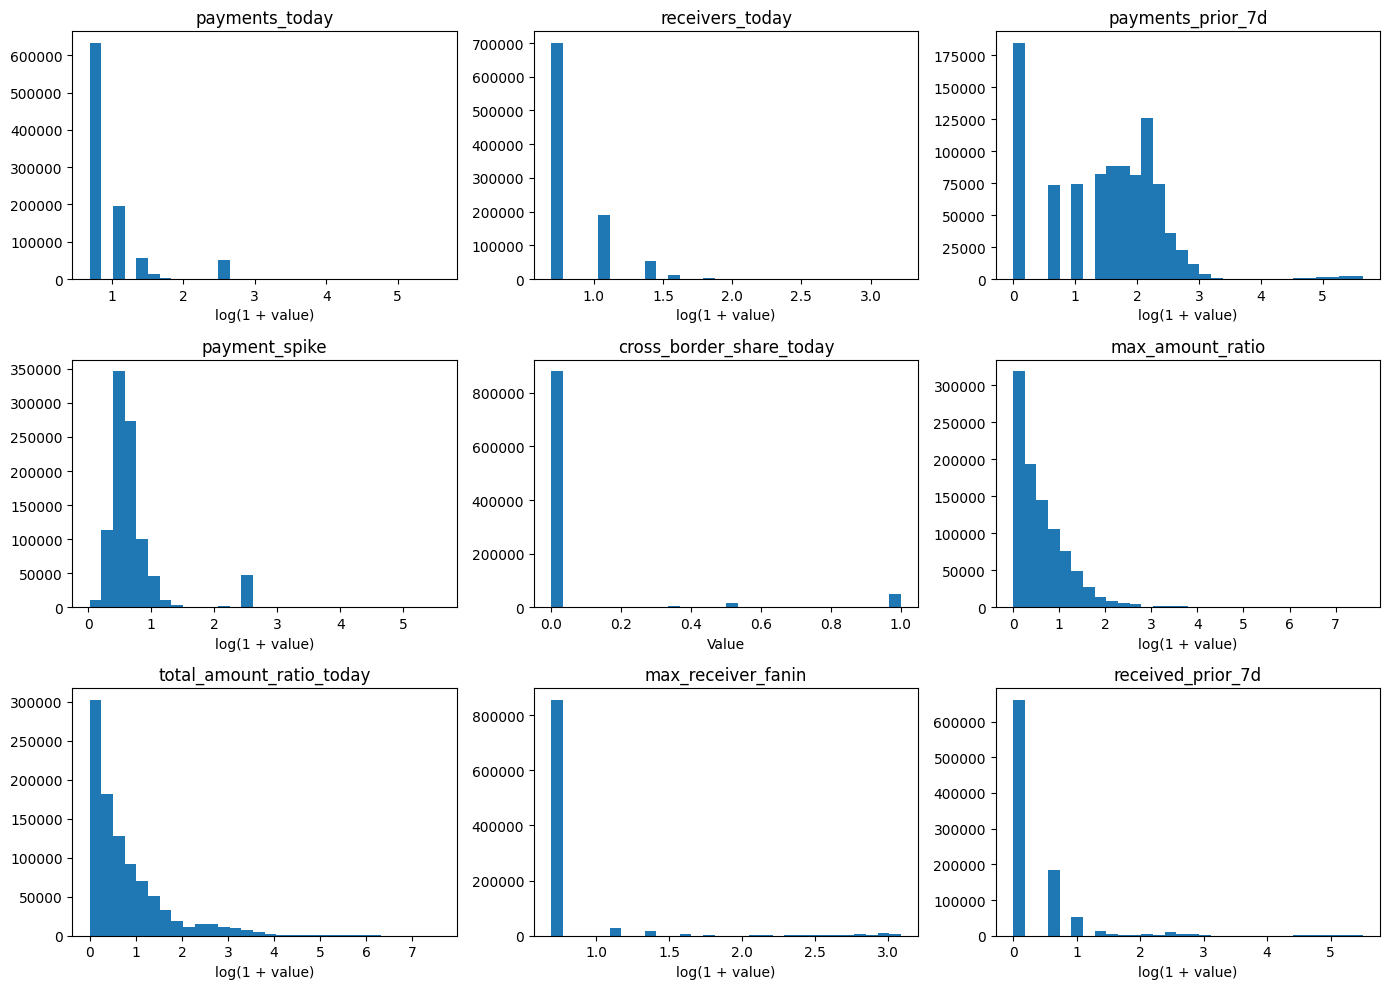

In [40]:

fig, axes = plt.subplots(3, 3, figsize=(14, 10))

for ax, col in zip(axes.flat, NUMERIC):
    if col == "cross_border_share_today":
        values = hist[col]
    else:values = np.log1p(hist[col])

    ax.hist(values, bins=30)
    ax.set_title(col)
    ax.set_xlabel("Value" if col == "cross_border_share_today" else "log(1 + value)")

plt.tight_layout()
plt.show()


The histograms showed that most sender days have low activity, but a smaller number of sender days have much higher payment counts and amounts.

Below, I'm checking how often each feature has the same value to see if any fail my 99.9% rule. I'm also checking whether the number of payments and receivers is usually the same.

In [41]:

for col in NUMERIC:
    most_common = hist[col].value_counts(normalize=True).iloc[0] * 100
    print(col, ":", round(most_common, 3), "%")

print("Payments equal receivers:",
      round((hist["payments_today"] == hist["receivers_today"]).mean() * 100, 2), "%")


payments_today : 66.01 %
receivers_today : 73.021 %
payments_prior_7d : 19.264 %
payment_spike : 15.339 %
cross_border_share_today : 91.749 %
max_amount_ratio : 0.001 %
total_amount_ratio_today : 0.001 %
max_receiver_fanin : 89.303 %
received_prior_7d : 68.988 %
Payments equal receivers: 90.82 %


All nine features passed my 99.9% rule, so none need to be removed for having too little variation.

One interesting thing was that 90.82% of sender days had the same number of payments and receivers. This leads me to think that those two features might be measuring similar things, which I'll check below.

I also found that 19.26% of sender days had no outgoing payments in the previous seven days. For these accounts, the payment spike feature equals today's payment count, so a high value doesn't always mean activity suddenly increased.

checking whether any of our 13 features are so closely related that we might not need both using Spearman correlation.

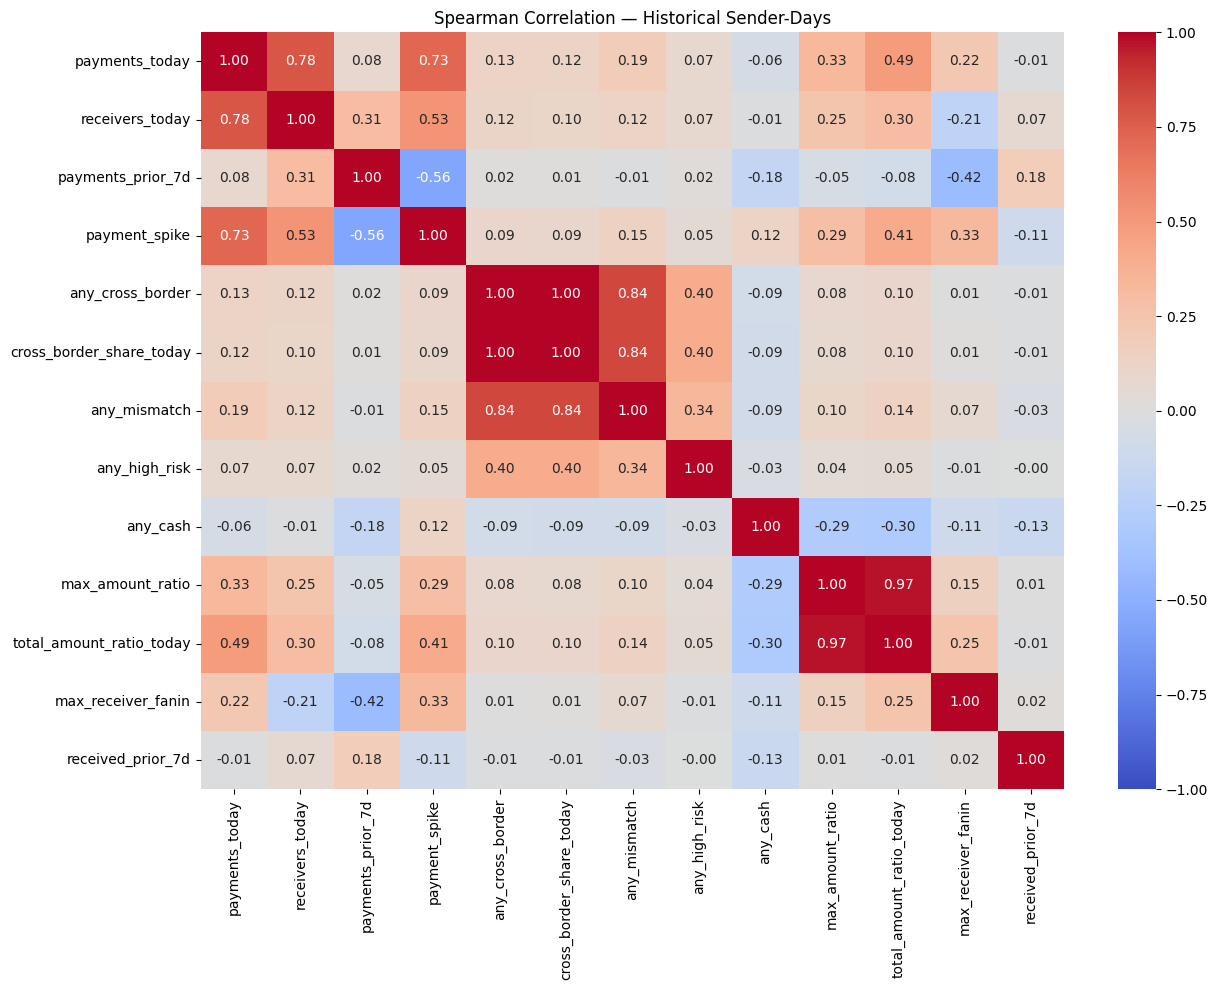

In [42]:

import seaborn as sns

corr = hist[FEATURES].corr(method="spearman")

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1)

plt.title("Spearman Correlation — Historical Sender-Days")
plt.tight_layout()
plt.show()


The heatmap shows two pairs of features with correlations above my 0.95 rule. I'm going to check their exact values before deciding which features to remove. I'm also looking at correlations above 0.80 to see which other features are closely related.

In [43]:

for i, feature in enumerate(FEATURES):
    for other in FEATURES[i + 1:]:
        r = corr.loc[feature, other]
        if abs(r) >= 0.80:
            print(feature, "/", other, ":", round(r, 4))


any_cross_border / cross_border_share_today : 0.9991
any_cross_border / any_mismatch : 0.8389
cross_border_share_today / any_mismatch : 0.8381
max_amount_ratio / total_amount_ratio_today : 0.9699


Two feature pairs exceeded my 0.95 correlation threshold. Cross-border share had a correlation of 0.9991 with the cross-border flag, while total amount ratio had a correlation of 0.9699 with maximum amount ratio.

Based on my rule, I'll remove cross_border_share_today and total_amount_ratio_today and keep the simpler features of any_cross_border and max_amount_ratio.

Based on the correlation results from above, I'm removing two features that were too similar to others. This leaves me with 11 features for modeling.

I'll separate them into behavioral and network-related features so I can test whether adding network information improves detection.

In [44]:

BEHAVIOR = [
    "payments_today", "receivers_today", "payments_prior_7d",
    "payment_spike", "any_cross_border", "any_mismatch",
    "any_high_risk", "any_cash", "max_amount_ratio"]

NETWORK = ["max_receiver_fanin", "received_prior_7d"]

LOCKED_FEATURES = BEHAVIOR + NETWORK

print("Stage A - Behavior features:", len(BEHAVIOR))
print("Stage B - Total features:", len(LOCKED_FEATURES))

feature_table = pd.DataFrame({
    "Feature": LOCKED_FEATURES,
    "Group": ["Behavior"] * len(BEHAVIOR) + ["Network"] * len(NETWORK)})

display(feature_table)


Stage A - Behavior features: 9
Stage B - Total features: 11


,Feature,Group
0,payments_today,Behavior
1,receivers_today,Behavior
2,payments_prior_7d,Behavior
3,payment_spike,Behavior
4,any_cross_border,Behavior
5,any_mismatch,Behavior
6,any_high_risk,Behavior
7,any_cash,Behavior
8,max_amount_ratio,Behavior
9,max_receiver_fanin,Network


The final feature list is now locked without using laundering labels to make these decisions.

Now that I've locked my final 11 features, I'm comparing normal and laundering sender days to see how their activity differs.

I'll compare typical values for the numerical features and how often the four risk indicators appear. This is only to understand the patterns, not to change which features I've selected.

In [45]:

NUMERIC_LOCKED = [col for col in LOCKED_FEATURES if col not in FLAGS]

print("Sender-days by label:")
print(hist["label"].value_counts().sort_index())

print("Typical values (medians):")
medians = hist.groupby("label")[NUMERIC_LOCKED].median().T
display(medians.rename(columns={0: "Normal", 1: "Laundering"}).round(2))

print("Risk indicator rates (%):")
rates = hist.groupby("label")[FLAGS].mean().T * 100
display(rates.rename(columns={0: "Normal", 1: "Laundering"}).round(2))



Sender-days by label:
label
0    956039
1      2203
Name: count, dtype: int64
Typical values (medians):


label,Normal,Laundering
payments_today,1.00,1.00
receivers_today,1.00,1.00
payments_prior_7d,4.00,2.00
payment_spike,0.82,1.00
max_amount_ratio,0.57,0.96
max_receiver_fanin,1.00,1.00
received_prior_7d,0.00,0.00


Risk indicator rates (%):


label,Normal,Laundering
any_cross_border,8.20,32.09
any_mismatch,11.21,39.40
any_high_risk,1.43,8.08
any_cash,13.81,26.51


The biggest differences were in the risk indicators. High risk receiver countries were about 5.7 times more common among laundering sender-days, while cross-border payments were about 3.9 times more common and currency mismatches about 3.5 times more common.

The median was 1 for both normal and laundering sender days across payment counts, receivers, and receiver fan in. This doesn't necessarily mean their activity is the same, so I'm checking how often each group has values greater than 1.

In [46]:

COUNT_FEATURES = ["payments_today", "receivers_today", "max_receiver_fanin"]

above_one = (hist[COUNT_FEATURES] > 1).groupby(hist["label"]).mean().T * 100

display(above_one.rename(columns={0: "Normal", 1: "Laundering"}).round(2))


label,Normal,Laundering
payments_today,34.01,27.24
receivers_today,26.98,24.56
max_receiver_fanin,10.70,9.67


The results here were supprising, I expected laundering sender days to have more activity but that wasnt the case here. Normal sender-days were actually more likely to have multiple payments at 34% vs. 27% for laundering, multiple receivers at 27% vs. 25% for laundering, and receiver fan-in greater than one at 10.7% vs. 9.7% for laundering.

Now im going to visualize an actual laundering pattern from the historical transactions.

I'm comparing normal fan in and laundering fan in transactions to see how their account networks look. Both involve multiple accounts sending money to one receiver, so I want to see whether the patterns look similar even though one is labeled as laundering.

In [47]:

for kind in ["normal_fan_in", "fan_in"]:
    subset = tx[
        (tx["Date"] <= CUTOFF) &
        (tx["Laundering_type"] == kind)
    ]

    counts = subset.groupby(["Date", "receiver_id"])["sender_id"].nunique()

    print(kind, "- historical transactions:", len(subset))
    print(counts.sort_values(ascending=False).head(3))


normal_fan_in - historical transactions: 558629
Date        receiver_id
2022-10-07  6833           20
2022-12-31  2399           20
2022-11-20  11978          20
Name: sender_id, dtype: int64
fan_in - historical transactions: 114
Date        receiver_id
2022-12-04  77198          5
2022-11-15  52231          4
2022-12-26  12846          3
Name: sender_id, dtype: int64


I looked for examples of normal and laundering fan in transactions where multiple senders paid the same receiver on the same day. However the results were somewhat unexpected  with the largest normal fan in group having 20 senders, compared to 5 senders for laundering.

I'm going to looking for a normal group with 5 senders below so I can compare two networks of similar size.

In [48]:

normal = tx[
    (tx["Date"] <= CUTOFF) &
    (tx["Laundering_type"] == "normal_fan_in")]

normal_counts = normal.groupby(["Date", "receiver_id"])["sender_id"].nunique()

print("Normal groups with 5 senders:", (normal_counts == 5).sum())
display(normal_counts[normal_counts == 5].head())


Normal groups with 5 senders: 0


,,sender_id
Date,receiver_id,


Suprisingly no normal fan in group had 5 senders.

Below I will look to see what normal group sizes are actually available

In [49]:
print("Normal fan-in group sizes:")
print(normal_counts.value_counts().sort_index())

Normal fan-in group sizes:
sender_id
7     246
8     248
9     234
10    226
11    234
12    231
13    259
14    254
15    237
16    247
17    242
18    278
19    268
20    232
Name: count, dtype: int64


The normal fan in groups ranged from 7 to 20 senders, while the largest laundering fan in group I found had 5. I'm going to compare a normal group with 7 senders to a laundering group with 5 to see how their networks look even though the number of senders isnt identical.

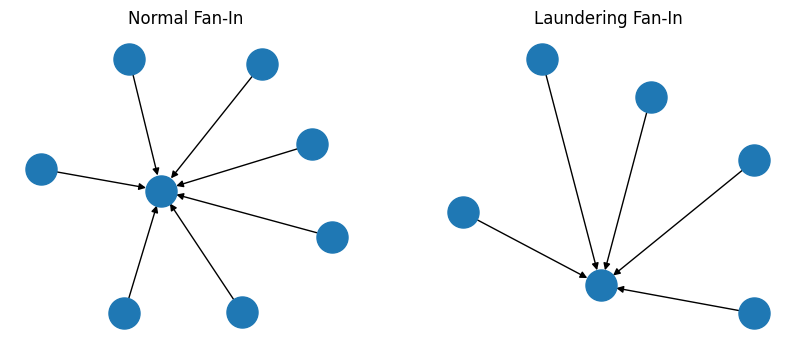

In [50]:

import networkx as nx
import matplotlib.pyplot as plt

# Selecting the two examples
day, receiver = normal_counts[normal_counts == 7].index[0]

normal_edges = normal[
    (normal["Date"] == day) & (normal["receiver_id"] == receiver)]

laundering_edges = tx[
    (tx["Date"] == "2022-12-04") &
    (tx["receiver_id"] == 77198) &
    (tx["Laundering_type"] == "fan_in")]

# Draw the networks
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, data, title in zip(
    axes,
    [normal_edges, laundering_edges],
    ["Normal Fan-In", "Laundering Fan-In"]):
    G = nx.from_pandas_edgelist(
        data, "sender_id", "receiver_id",
        create_using=nx.DiGraph())
    nx.draw(G, ax=ax, with_labels=False, node_size=500, arrows=True)
    ax.set_title(title)

plt.show()


Both networks show multiple accounts sending money to one receiver. The normal network had 7 senders compared with 5 in the laundering network. However, the diagrams didnt tell me much about how the activity differs.

I'm going to look at the receivers transaction histories to see whether their payments occurred over multiple days and whether the laundering payments were all labeled under the same typology.

In [51]:
hub = tx[
    (tx["Date"] <= CUTOFF) &
    (tx["receiver_id"] == 77198) &
    (tx["Is_laundering"] == 1)]

print("Laundering hub by typology:")
display(
    hub.groupby("Laundering_type", observed=True)
    .agg(payments=("Date", "size"), days=("Date", "nunique")))

normal_hub = normal[normal["receiver_id"] == receiver]

print("Normal fan-in hub:")
print("Days:", normal_hub["Date"].nunique())
print("Payments:", len(normal_hub))


Laundering hub by typology:


,payments,days
Laundering_type,,
fan_in,12,6


Normal fan-in hub:
Days: 1
Payments: 61


The normal receiver had 61 payments in one day and the laundering receiver had 12 payments across 6 days. All 12 of the laundering payments were labeled fan_in, but I am unable to tell if they were part of the same scheme.

This shows a possible limitation in my network features. My max_receiver_fanin feature only looks at one day, so it doesn't measure how a receiver's connections change over time.

However these are only two examples, so I can't say this is always the case. A future improvement could be adding a feature that tracks a receiver's activity over the previous 7 days.

# Part D - Final Feature Selection Summary


*   All 13 features passed the data quality check
* I removed 2 features that duplicated others:
  * cross-border share (almost identical to the cross-border flag)
  * total daily amount (almost identical to the largest payment, since most days have one payment)
* Final list: 11 features. 9 behavior features for Stage A, plus 2 network features added in Stage B
* Laundering days were 2–6× more likely to involve cash, cross-border payments, currency mismatches, or high-risk countries, but no single flag caught most laundering
* Laundering days weren’t busier than normal days. Laundering fan-ins were smaller (5 senders at most) and spread over several days, while normal fan-ins had 7–20 senders in one day
* The one-day network features may not help much. Multi-day versions are a future improvement
   



# Part E - Key Findings


*   Laundering is rare (about 1 in 406 sender-days), so accuracy would be misleading. Systems are judged on how many cases they catch with 50 reviews a day
* The review limit of 50 per day is theoretically enough to catch almost every laundering sender-day in the dataset, but only if the system ranks them correctly.
* The warning signs are useful but weak on their own, so the models need to combine them
* Laundering is spread across days, which limits features that look at one day at a time
* Next: notebook 04 compares rules, logistic regression, and boosted trees using the 9 behavior features

